In [4]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# This script provides the masked data for infilling based downscalling.
# It needs file with original grid (e.g. 0.1 degree) and file with upscaled data (e.g., 1 degree)
# Mask: 0 for points to be infilled, 1 for values to use for infilling.
# Masked_data: HR grid with HR values, except mask==1 where LR data is inserted 

In [6]:
year_min = 1950
year_max = 2024
year_ref_min=1985
year_ref_max=2014
var = 't2max'

In [7]:
# Only keep years with 365 days, remove leap years
def remove_leap_days(ds):
    # Get day-of-year for each time step
    day_of_year = ds['time'].dt.dayofyear
    # Keep only days <= 365 (i.e., remove Feb 29)
    ds_corrected = ds.sel(time=day_of_year <= 365)
    return ds_corrected

In [10]:
for year in range(year_min,year_max+1):
    # ========= load high resolution data ==============
    path = '/work/uo1075/u241308/data_python_PostDoc/BB_challenge/data/era5_land/'+var+'/highres/anomalies/'
    file = 'era5_land_'+var+'_daily_'+str(year)+'_europe_anomalies_ref_'+str(year_ref_min)+'_'+str(year_ref_max)+'.nc'
    
    original_data = xr.open_dataset(path+file).t2m
    #original_data = original_data.rename({'longitude': 'lon','latitude': 'lat'})
    #original_data = original_data.rename({'valid_time': 'time'})
    original_data = remove_leap_days(original_data) #leap years to 365
    
    # ========= load low resolution data ==============
    path = '/work/uo1075/u241308/data_python_PostDoc/BB_challenge/data/era5_land/'+var+'/lowres/anomalies/'
    file = 'era5_land_'+var+'_daily_'+str(year)+'_europe_anomalies_ref_'+str(year_ref_min)+'_'+str(year_ref_max)+'_1degree.nc'
    
    coarse_data = xr.open_dataset(path+file).t2m
    #coarse_data = coarse_data.rename({'longitude': 'lon','latitude': 'lat'})
    #coarse_data = coarse_data.rename({'valid_time': 'time'})
    coarse_data = remove_leap_days(coarse_data) #leap years to 365
    
    #new longitudes
    coarse_data['longitude'] = np.where(coarse_data.longitude > 180,coarse_data.longitude-360,coarse_data.longitude)
    ind_sort = np.argsort(coarse_data.longitude)
    coarse_data = coarse_data[:,:,ind_sort.values]
    
    # ========= create a mask with high resolution data ==============
    # High-res coordinates
    lat_hr = original_data.latitude.values
    lon_hr = original_data.longitude.values
    dlat = abs(lat_hr[1] - lat_hr[0])
    dlon = abs(lon_hr[1] - lon_hr[0])
    lat0 = lat_hr[0]   # e.g. 72.0
    lon0 = lon_hr[0]   # e.g. -15.0
    
    # Compute high-res indices of coarse grid centers
    #ilat = np.round((lat0 - coarse_data.lat.values) / dlat).astype(int) #this was for descending latitudes
    ilat = np.round((coarse_data.latitude.values - lat0) / dlat).astype(int) #for ascending latitudes, inverted with CDO
    ilon = np.round((coarse_data.longitude.values - lon0) / dlon).astype(int)
    
    # Valid indices
    lat_valid = (ilat >= 0) & (ilat < lat_hr.size)
    lon_valid = (ilon >= 0) & (ilon < lon_hr.size)
    
    ilat = ilat[lat_valid]
    ilon = ilon[lon_valid]
    
    # Reduce coarse data accordingly
    coarse_valid = coarse_data.isel(
        latitude=np.where(lat_valid)[0],
        longitude=np.where(lon_valid)[0],
    )
    
    #create masked file
    masked_data = original_data.copy()
    masked_data[:] = 0
    masked_data = masked_data.where(~np.isnan(original_data), other=np.nan)  # keep ocean NaNs
    
    # Set the coarse values at the centers
    masked_data.values[:,ilat[:, None],ilon[None, :]] = coarse_valid.values

    # ======== Create a mask file and save - WITH TIME DIMENSION ================
    # 0 for gridpoints to infill
    # 1 for ocean gridpoints and the coarse data values
    mask = xr.where(masked_data==0,0,1)
    path = '/work/uo1075/u241308/data_python_PostDoc/BB_challenge/data/era5_land/'+var+'/mask/anomalies/'
    file = 'era5_land_'+var+'_daily_'+str(year)+'_europe_anomalies_ref_'+str(year_ref_min)+'_'+str(year_ref_max)+'_binary_mask.nc'
    mask.to_netcdf(path+file)

    # ============= use HR values where not used for infilling (downscalling) ==============
    masked_data = xr.where(masked_data==0,original_data,masked_data)

    # ============= set regrided ocean nans to zeros ==============
    masked_data_to_test = xr.where(np.isnan(masked_data),0,masked_data) #includes all gridpoints onshore due to remapcon
    masked_data = xr.where(np.isnan(original_data),0,masked_data) #exclude all gridpoints onshore
    
    # ================ save low res data on high res grid + data =============
    path = '/work/uo1075/u241308/data_python_PostDoc/BB_challenge/data/era5_land/'+var+'/lowres_in_highres_grid/anomalies/'
    file = 'era5_land_'+var+'_daily_'+str(year)+'_europe_anomalies_ref_'+str(year_ref_min)+'_'+str(year_ref_max)+'_lowres_values_in_highres_grid.nc'    
    masked_data.to_netcdf(path+file)

    # ================ high res data in high res grid, with zeros as in masked_data =============
    highres_masked = xr.where(masked_data != 0, original_data, masked_data)
    path = '/work/uo1075/u241308/data_python_PostDoc/BB_challenge/data/era5_land/'+var+'/lowres_in_highres_grid/anomalies/'
    file = 'era5_land_'+var+'_daily_'+str(year)+'_europe_anomalies_ref_'+str(year_ref_min)+'_'+str(year_ref_max)+'_highres_values_in_highres_grid.nc'    
    highres_masked.to_netcdf(path+file)
    
    print('Year '+str(year)+' done')

Year 1950 done
Year 1951 done
Year 1952 done
Year 1953 done
Year 1954 done
Year 1955 done
Year 1956 done
Year 1957 done
Year 1958 done
Year 1959 done
Year 1960 done
Year 1961 done
Year 1962 done
Year 1963 done
Year 1964 done
Year 2001 done
Year 2002 done
Year 2003 done
Year 2004 done
Year 2005 done
Year 2006 done
Year 2007 done
Year 2008 done
Year 2009 done
Year 2010 done
Year 2011 done
Year 2012 done
Year 2013 done
Year 2014 done
Year 2015 done
Year 2016 done
Year 2017 done
Year 2018 done
Year 2019 done
Year 2020 done
Year 2021 done
Year 2022 done
Year 2023 done
Year 2024 done


# Sanity check

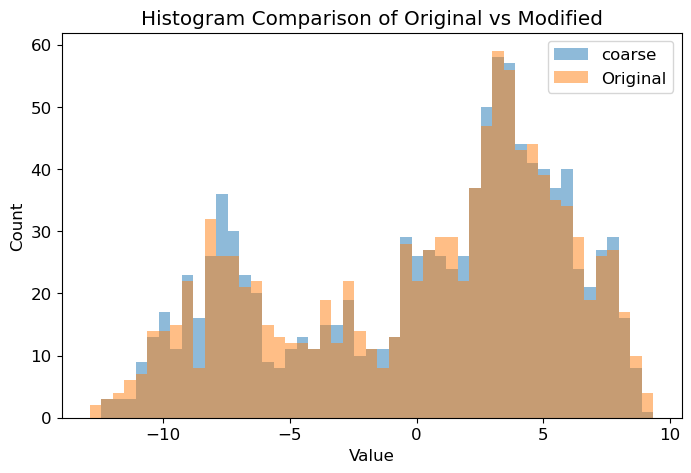

In [27]:
#both histograms should be different: data to be used for infilling in masked_data should be low resolution, while the high resolution file should have HR values
low_res_mask_joker = xr.where(mask[0]==1,masked_data[0],np.nan)
low_res_mask_joker = xr.where(low_res_mask_joker==0,np.nan,low_res_mask_joker)
low_res_mask_joker = low_res_mask_joker.values.flatten()
low_res_mask_joker = low_res_mask_joker[~np.isnan(low_res_mask_joker)]

high_res_mask_joker = xr.where(mask[0]==1,highres_masked[0],np.nan)
high_res_mask_joker = xr.where(high_res_mask_joker==0,np.nan,high_res_mask_joker)
high_res_mask_joker = high_res_mask_joker.values.flatten()
high_res_mask_joker = high_res_mask_joker[~np.isnan(high_res_mask_joker)]

bins = np.linspace(
    min(high_res_mask_joker.min(), high_res_mask_joker.min()),
    max(high_res_mask_joker.max(), high_res_mask_joker.max()),
    50
)

# Plot histogram
plt.figure(figsize=(8,5))
plt.hist(low_res_mask_joker, bins=bins, alpha=0.5, label='coarse')
plt.hist(high_res_mask_joker, bins=bins, alpha=0.5, label='Original')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Histogram Comparison of Original vs Modified")
plt.legend()
plt.show()

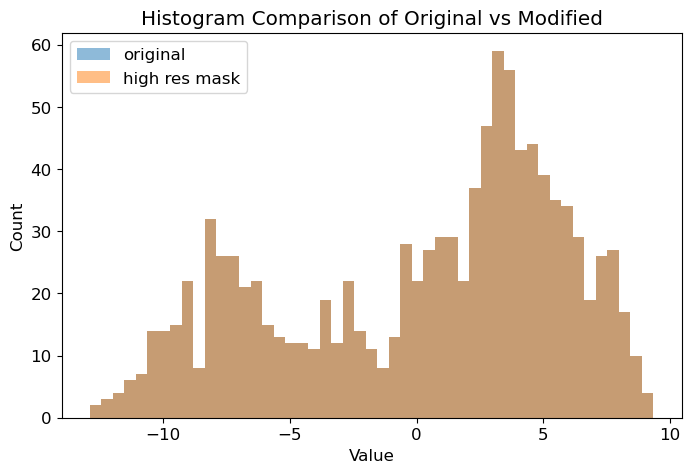

In [29]:
#both histograms should be identical, both HR values
high_res_joker = xr.where(mask[0]==1,original_data[0],np.nan)
high_res_joker = high_res_joker.values.flatten()
high_res_joker = high_res_joker[~np.isnan(high_res_joker)]

high_res_mask_joker = xr.where(mask[0]==1,highres_masked[0],np.nan)
high_res_mask_joker = xr.where(high_res_mask_joker==0,np.nan,high_res_mask_joker)
high_res_mask_joker = high_res_mask_joker.values.flatten()
high_res_mask_joker = high_res_mask_joker[~np.isnan(high_res_mask_joker)]

bins = np.linspace(
    min(high_res_joker.min(), high_res_joker.min()),
    max(high_res_joker.max(), high_res_joker.max()),
    50
)

# Plot histogram
plt.figure(figsize=(8,5))
plt.hist(high_res_joker, bins=bins, alpha=0.5, label='original')
plt.hist(high_res_mask_joker, bins=bins, alpha=0.5, label='high res mask')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Histogram Comparison of Original vs Modified")
plt.legend()
plt.show()

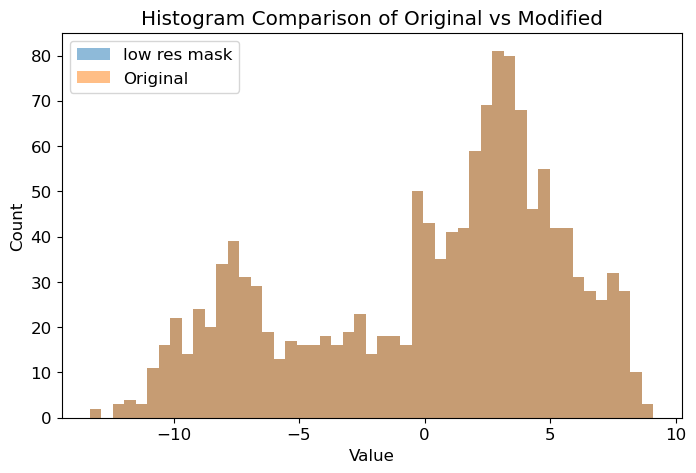

In [31]:
#both histograms should be identical
low_res_joker = coarse_data[0].values.flatten()
low_res_joker = low_res_joker[~np.isnan(low_res_joker)]

low_res_mask_joker = xr.where(mask[0]==1,masked_data_to_test[0],np.nan)
low_res_mask_joker = xr.where(low_res_mask_joker==0,np.nan,low_res_mask_joker)
low_res_mask_joker = low_res_mask_joker.values.flatten()
low_res_mask_joker = low_res_mask_joker[~np.isnan(low_res_mask_joker)]

bins = np.linspace(
    min(low_res_joker.min(), low_res_joker.min()),
    max(low_res_joker.max(), low_res_joker.max()),
    50
)

# Plot histogram
plt.figure(figsize=(8,5))
plt.hist(low_res_mask_joker, bins=bins, alpha=0.5, label='low res mask')
plt.hist(low_res_joker, bins=bins, alpha=0.5, label='Original')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Histogram Comparison of Original vs Modified")
plt.legend()
plt.show()

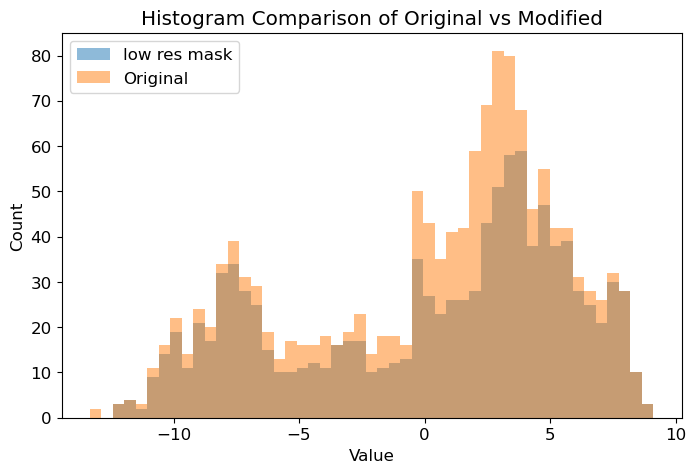

In [35]:
#both histograms should be different, with original above mask data, because we excluded onshore gridpoints, artifact of remapcon upscaling 
low_res_joker = coarse_data[0].values.flatten()
low_res_joker = low_res_joker[~np.isnan(low_res_joker)]

low_res_mask_joker = xr.where(mask[0]==1,masked_data[0],np.nan)
low_res_mask_joker = xr.where(low_res_mask_joker==0,np.nan,low_res_mask_joker)
low_res_mask_joker = low_res_mask_joker.values.flatten()
low_res_mask_joker = low_res_mask_joker[~np.isnan(low_res_mask_joker)]

bins = np.linspace(
    min(low_res_joker.min(), low_res_joker.min()),
    max(low_res_joker.max(), low_res_joker.max()),
    50
)

# Plot histogram
plt.figure(figsize=(8,5))
plt.hist(low_res_mask_joker, bins=bins, alpha=0.5, label='low res mask')
plt.hist(low_res_joker, bins=bins, alpha=0.5, label='Original')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Histogram Comparison of Original vs Modified")
plt.legend()
plt.show()

Text(0.5, 1.0, 'Masked Data (non-NaN points)')

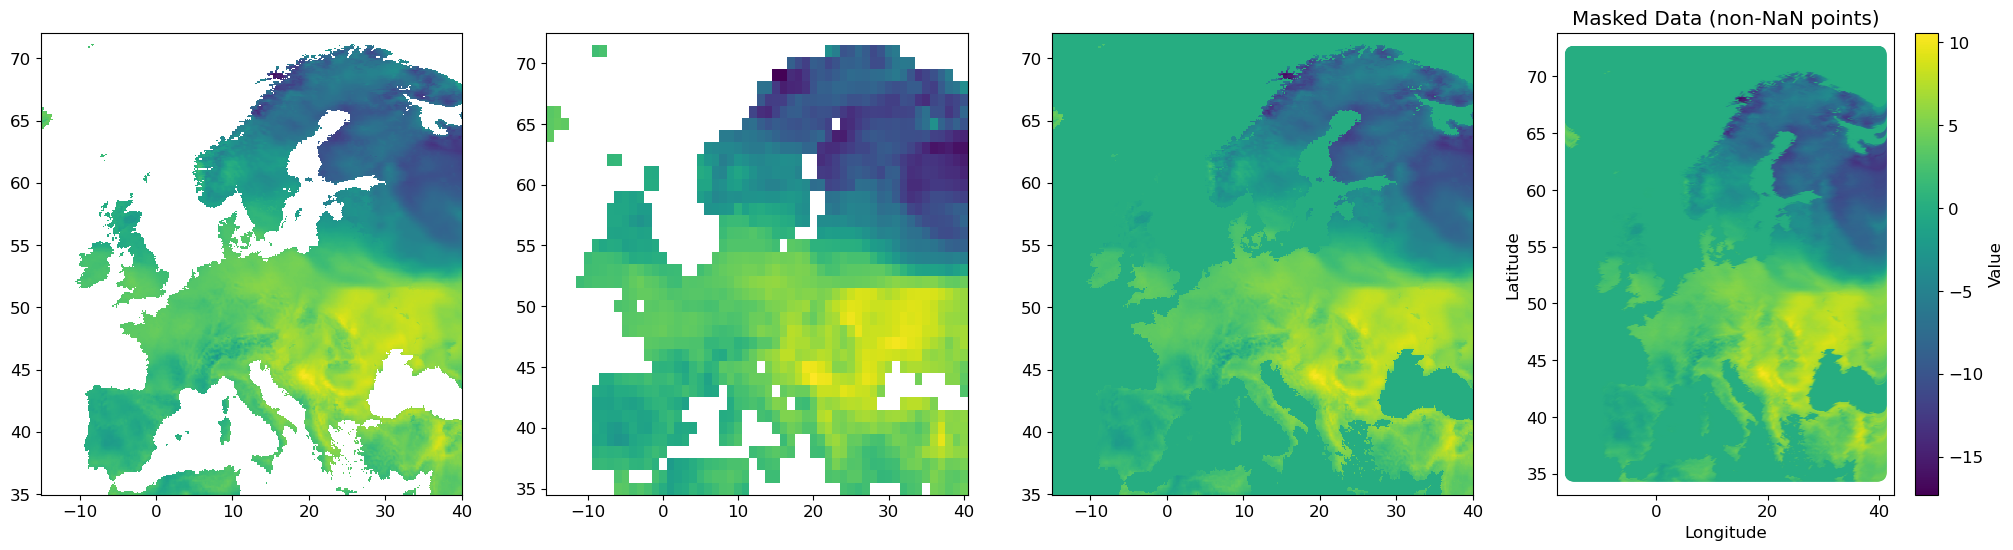

In [36]:
#Plot
row = 1
column = 4

fig = plt.figure(figsize=(25,6))#(22,15))
plt.rcParams.update({'font.size': 12})

ax1 = fig.add_subplot(row,column,1)
plt.pcolormesh(original_data.longitude,original_data.latitude,original_data[0])

ax2 = fig.add_subplot(row,column,2)
plt.pcolormesh(coarse_data.longitude,coarse_data.latitude,coarse_data[0])

ax3 = fig.add_subplot(row,column,3)
plt.pcolormesh(masked_data.longitude,masked_data.latitude,masked_data[0])

ax4 = fig.add_subplot(row,column,4)
# Get coordinates and values of non-NaN points
lat = masked_data.latitude.values
lon = masked_data.longitude.values
values = masked_data.values  # shape: (time, lat, lon)

# For simplicity, pick one time slice, e.g., first one
data_slice = values[0]  # shape: (lat, lon)
lat_grid, lon_grid = np.meshgrid(lat, lon, indexing='ij')

# Mask NaNs
mask_joker = ~np.isnan(data_slice)
plt.scatter(lon_grid[mask_joker], lat_grid[mask_joker], c=data_slice[mask_joker], s=100, cmap='viridis')
plt.colorbar(label='Value')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Masked Data (non-NaN points)')

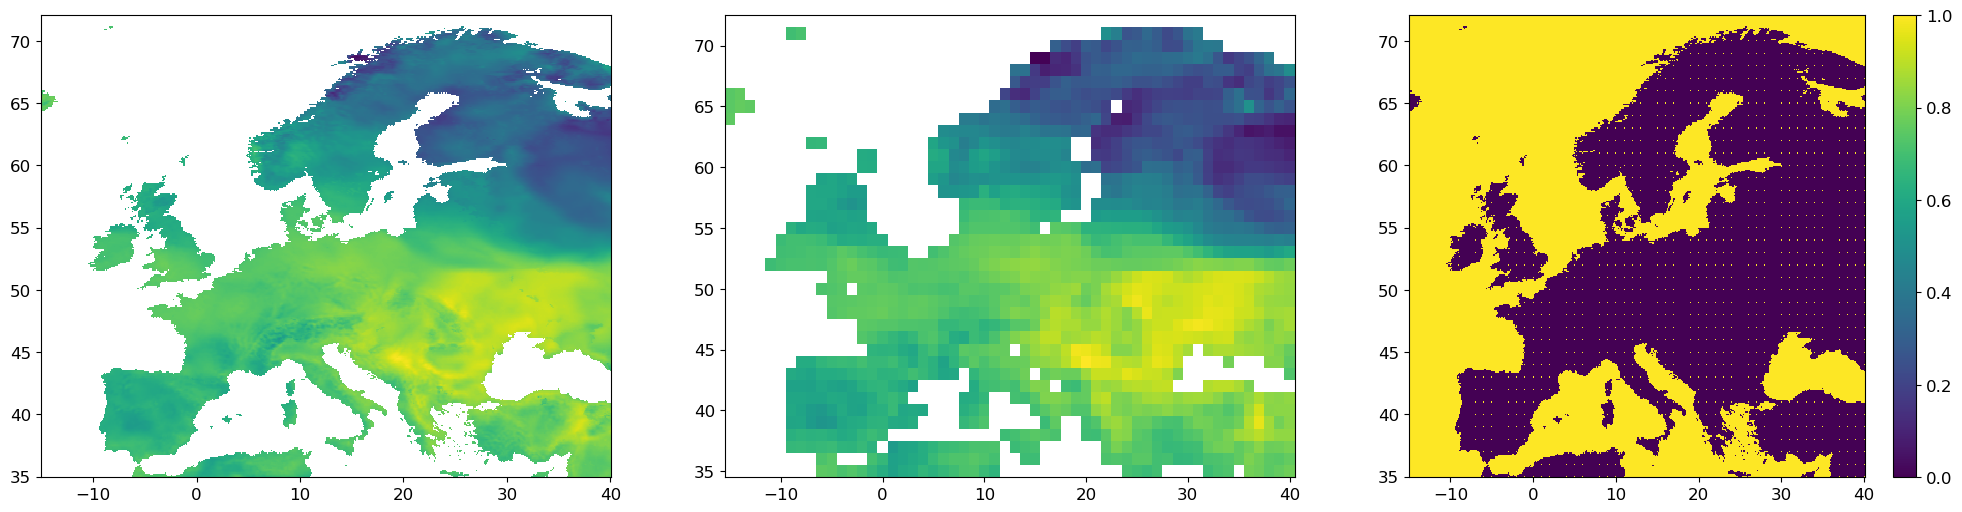

In [37]:
row = 1
column = 3

fig = plt.figure(figsize=(25,6))#(22,15))
plt.rcParams.update({'font.size': 12})

ax1 = fig.add_subplot(row,column,1)
plt.pcolormesh(original_data.longitude,original_data.latitude,original_data[0])

ax2 = fig.add_subplot(row,column,2)
plt.pcolormesh(coarse_data.longitude,coarse_data.latitude,coarse_data[0])

ax3 = fig.add_subplot(row,column,3)
plt.pcolormesh(original_data.longitude,original_data.latitude,mask[0])
plt.colorbar()

In [12]:
# none of the files should have nans

# Idea 1: 
# input: high resolution data, mask file => training
# reconstruct: low resolution data
# downside: might loose spatial variability as the training only sees high resolution, but reconstruct low resolution. Link between low and high resolution.

# Idea 2:
# INput: low resolution data, mask file => training
# downside: the exact point (1/10) will be missing. 
